# ¿Cuánto aviso nos da un río? · 09 — Síntesis del estudio

**Curso:** Ciencia de Datos Ambientales (CDA) · Universidad de Ingeniería y Tecnología (UTEC) · Proyecto Integrador

**Equipo:** 

- Luis Angel Cupe Espinoza
- Yely Lanasca Justiniano 
- Lia Kim Alcantara Tineo 
- Mayra Madelyn Marzano Mejia 
- María Fernanda Torres Carbajal 

**Protocolo:** común a todo el estudio (`comun.py`; identificado como `v4` en el código y en las salidas). Cada etapa registra en su resumen el protocolo y el modo de ejecución, y cada archivo que se usa aquí se verifica contra `salidas/manifiesto.json`.

**Este cuaderno no entrena ningún modelo, no implementa reglas propias y no hace otra selección.** Lee las salidas de 01–08 **solo después de comprobar** que pertenecen al mismo protocolo, a una ejecución compatible y final, y que cada archivo coincide con el manifiesto; vuelve a evaluar los avisos **desde las trayectorias guardadas con la misma función** `comun.evaluar_avisos`; y reúne las respuestas del estudio con la selección del 08, conservando su incertidumbre, la escasez de eventos, la disponibilidad supuesta de los datos y el uso previo de la prueba.

**Alcance:** las respuestas resumen una **comparación académica de configuraciones** evaluadas retrospectivamente; no describen un sistema operativo de alerta.

---
## 0. Planteamiento integrado

### 0.1 Pregunta principal
> **¿Cuánto aviso nos da un río?** En dos ríos peruanos de memoria hidrológica muy distinta —Racarumi (Chancay-Lambayeque, andino, 2 363 km²) y Tamshiyacu (Amazonas, ~720 000 km²)—, ¿hasta qué horizonte se pronostica bien la **magnitud** del caudal diario y con cuántos días **reales** se puede anticipar un **nuevo cruce** del P95, y cuánto cambian esas dos respuestas al agregar información (estaciones aguas arriba, lluvia de la cuenca) o al usar un modelo fundacional sin ajuste local de sus pesos?

### 0.2 Preguntas específicas y cuaderno que las responde
| | Pregunta | Cuadernos |
|---|---|---|
| P1 | ¿Hasta qué horizonte pronostican la magnitud del caudal seis modelos que solo usan el caudal local y el calendario, frente a persistencia y climatología? ¿Difiere entre los dos ríos? | 01, 02, 03 |
| P2 | Con esas mismas fuentes (caudal local y calendario), ¿con cuántos días reales se avisan los nuevos cruces del P95, con cuántas omisiones y falsas alarmas? | 04 |
| P3 | ¿Cuánto aporta el caudal de las estaciones aguas arriba **inmediatas** (cada una por separado) a la magnitud y al horizonte útil, con los seis modelos? | 05 |
| P4 | ¿Cuánto aporta la lluvia de la cuenca y sus índices antecedentes, según **qué lluvia esté disponible** al emitir, con los seis modelos? | 06 |
| P5 | ¿Un modelo fundacional con sus pesos publicados, sin ajuste local (Chronos-2), compite con los modelos entrenados con las mismas fuentes y disponibilidad (con representaciones específicas por modelo), y qué tan útil es su distribución predictiva? | 07, 08 |
| P6 | **Selección final:** con todas las combinaciones implementadas y las siete familias, ¿qué configuración se elige en validación para la magnitud y cuál para avisar crecidas, en cada cuenca y según la disponibilidad de los datos, y cómo rinden en la prueba? | 08 |

### 0.3 Dos resultados distintos
| Resultado | Qué se evalúa | Medidas |
|---|---|---|
| **Pronóstico del caudal** | Precisión de la magnitud por horizonte | NSE, RMSE, ganancia G(h) = 1 − MSE/MSE_ref, **horizonte útil** H (cota 95 %) frente a persistencia y climatología |
| **Anticipación de crecidas** | Detección de **nuevos** cruces del P95 de entrenamiento | aciertos, omisiones, falsas alarmas; POD, FAR, CSI; anticipación real; POD(A) con su denominador |

Una mejora de precisión **no implica** más días de anticipación: hay que evaluarla con eventos. Y un cruce del P95 es un **caudal elevado** bajo una definición estadística, no una inundación ni un daño.

### 0.4 Escenarios de disponibilidad (los mismos en 05–09)
| Escenario | Qué supone |
|---|---|
| **Mismo día** | Las fuentes externas (lluvia, índices antecedentes, estaciones aguas arriba) se conocen hasta el día de emisión t. Es retrospectivo: PISCOp no se publica en tiempo real y CAMELS-PE no informa la hora de corte del acumulado; **no está demostrado que ese dato esté disponible a tiempo**. |
| **Un día de retraso** | Las fuentes externas llegan hasta t−1. Es el más cercano a una operación con estos productos. El caudal local se supone disponible hasta t en ambos. |
| **Lluvia futura observada (idealizado)** | Se usa la lluvia observada de t + 1 a t + h como si se conociera al emitir. Mide el beneficio de esa información con estos modelos; **no compite** en la selección (06 §10, 07 §7). |

In [1]:
import hashlib, json, os, platform, warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import comun as C
import aguas_arriba as A
import lluvia as LL
import integrado as I

%matplotlib inline
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 80)

SAL = C.ruta_salidas()                               # 'salidas' (final) o 'salidas_rapido' (modo rápido)
RUTA_FIG, RUTA_TAB = SAL / 'sintesis' / 'figuras', SAL / 'sintesis' / 'tablas'
for r in (RUTA_FIG, RUTA_TAB):
    r.mkdir(parents=True, exist_ok=True)
EST = ['Racarumi', 'Tamshiyacu']
H = len(C.HORIZONTES)
AV = C.AVISO
B = 50 if C.es_rapido() else 1000
print(f"Ejecución: {datetime.now():%Y-%m-%d %H:%M} | Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"protocolo {C.VERSION} | modo rápido: {C.es_rapido()}")

Ejecución: 2026-11-22 23:39 | Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | protocolo v4 | modo rápido: False


---
## 1. ¿Las salidas son compatibles?
Cuatro comprobaciones antes de calcular nada: (a) `comun.verificar_resumen` exige que cada etapa sea del mismo protocolo, de una ejecución declarada compatible (`C.REVISIONES_COMPATIBLES`) y de la ejecución final (no del modo rápido); (b) **antes de leer** cada archivo, `comun.verificar_archivos` exige `salidas/manifiesto.json` y que su huella SHA-256 coincida: un archivo alterado, ausente del manifiesto o un manifiesto faltante **detienen** la síntesis (en modo rápido no hay manifiesto y todo queda marcado «no validado»); (c) `comun.verificar_insumos` comprueba que los **insumos originales** que se vuelven a cargar (series y atributos de CAMELS-PE, tablas de depuración de los EDA) y el código de los módulos coinciden con las huellas del manifiesto; (d) las fechas de emisión y los caudales observados coinciden entre etapas.
**Por qué:** combinar en una síntesis archivos de ejecuciones o configuraciones distintas produciría comparaciones sin sentido.

In [2]:
ETAPAS = {'racarumi': '01', 'tamshiyacu': '02', 'anticipacion': '04', 'aguas_arriba': '05', 'lluvia': '06', 'chronos': '07', 'entradas': '08'}
RES = {k: C.verificar_resumen(SAL / k / 'resumen.json') for k in ETAPAS}
# Todos los archivos que usa esta síntesis se verifican AQUÍ, antes de calcular o escribir nada.
T08 = ['tabla_final.csv', 'tabla_seleccion_magnitud_prueba.csv', 'tabla_seleccion_magnitud_validacion.csv', 'tabla_seleccion_avisos.csv',
       'tabla_avisos_racarumi.csv', 'tabla_metricas_prueba.csv', 'tabla_prueba_frente_a_seleccionada.csv', 'tabla_matriz_experimentos.csv',
       'tabla_registro_verificaciones.csv', 'tabla_cruces_evaluables.csv', 'tabla_tamshiyacu_combinaciones_prueba.csv',
       'tabla_tamshiyacu_requena_combinaciones_prueba.csv', 'tabla_entradas_reales.csv']
ARCHIVOS = [f'{k}/resumen.json' for k in ETAPAS] + [f'{k}/predicciones.npz' for k in ['racarumi', 'tamshiyacu', 'lluvia', 'chronos', 'aguas_arriba']] + [f'entradas/predicciones_{e}.npz' for e in ['racarumi', 'tamshiyacu']] + \
    [f'{e}/tablas/tabla_metricas_prueba.csv' for e in ['racarumi', 'tamshiyacu']] + ['anticipacion/tablas/tabla_anticipacion_prueba.csv'] + \
    [f'{k}/tablas/tabla_efecto_entrada_prueba.csv' for k in ['aguas_arriba', 'lluvia']] + ['entradas/tablas/' + t for t in T08]
VERIFICADOS = {f['archivo'] for f in C.verificar_archivos([SAL / a for a in ARCHIVOS]) if f['validado']} if not C.es_rapido() else set()
# Insumos ORIGINALES: series de CAMELS-PE, tablas de depuración de los EDA y código de los módulos, contra las huellas
# del manifiesto; si un insumo cambió después de la ejecución, la síntesis se detiene antes de calcular
INSUMOS = C.verificar_insumos()
print(f"Salidas verificadas contra el manifiesto: {len(VERIFICADOS)} | insumos originales y código verificados: "
      f"{sum(f['validado'] for f in INSUMOS)} de {len(INSUMOS)}")
LEIDOS = []

def leer(ruta, **kw):
    # Verifica la huella del archivo contra el manifiesto ANTES de leerlo (se detiene si no coincide) y lo registra.
    ruta = Path(ruta)
    LEIDOS.extend(C.verificar_archivos([ruta]))
    assert C.es_rapido() or LEIDOS[-1]['archivo'] in VERIFICADOS, f'{ruta}: no estaba en la lista verificada al inicio'
    if ruta.suffix == '.npz':
        return np.load(ruta, allow_pickle=False)
    if ruta.suffix == '.json':
        return json.loads(ruta.read_text(encoding='utf-8'))
    return pd.read_csv(ruta, **kw)

Z = {k: leer(SAL / k / 'predicciones.npz') for k in ['racarumi', 'tamshiyacu', 'lluvia', 'chronos', 'aguas_arriba']}
Z8 = {e: leer(SAL / 'entradas' / f'predicciones_{e.lower()}.npz') for e in EST}
T = {t: leer(SAL / 'entradas' / 'tablas' / t) for t in T08}
D = {}
for e in EST:
    q, _ = C.cargar_serie(e)
    z = Z[e.lower()]
    fp = pd.to_datetime(z['fechas_pru'], unit='D')
    D[e] = dict(q=q, P95=RES[e.lower()]['P95'], eps=RES[e.lower()]['eps'], f_p=fp, f_v=pd.to_datetime(z['fechas_val'], unit='D'),
                obs=z['obs_pru'].astype(float))
    # misma prueba y mismos caudales en 01/02, 06 y 07 (todas las emisiones de la estación)
    f06 = pd.DatetimeIndex(Z['lluvia'][f'{e}|Q|fechas_pru'])
    f07 = pd.DatetimeIndex(Z['chronos'][f'{e}|Q|fechas'])
    assert f06.equals(fp), f'{e}: 06 no usa las emisiones de prueba de 01/02'
    assert fp.isin(f07).all(), f'{e}: Chronos-2 (07) no cubre las emisiones de prueba de 01/02'
    assert np.allclose(Z['lluvia'][f'{e}|Q|obs_pru'], D[e]['obs']), f'{e}: observaciones distintas entre 01/02 y 06'
    assert RES['anticipacion']['P95'][e] == D[e]['P95'], f'{e}: P95 distinto entre 01/02 y 04'
    D[e]['pos07'] = f07.get_indexer(fp)
# 08: Racarumi en las emisiones de 01/02 y 06; Tamshiyacu en las filas con San Regis (05), un subconjunto
f08R = pd.DatetimeIndex(Z8['Racarumi']['Racarumi|Q|fechas_pru'])
assert f08R.equals(D['Racarumi']['f_p']), 'Racarumi: el 08 no usa las emisiones de prueba de 01/02'
f08T = pd.DatetimeIndex(Z8['Tamshiyacu']['Tamshiyacu|Q|fechas_pru'])
assert f08T.equals(pd.DatetimeIndex(Z['aguas_arriba']['Tamshiyacu|Q|fechas_pru'])) and f08T.isin(D['Tamshiyacu']['f_p']).all()
compat = pd.DataFrame([{'etapa': k, 'cuaderno': v, 'protocolo': RES[k]['version'],
                        'ejecución rápida': RES[k]['rapido']} for k, v in ETAPAS.items()]).set_index('etapa')
print(f'Archivos verificados contra el manifiesto antes de calcular nada: {len(VERIFICADOS)} (todos coinciden; si no, la ejecución se habría detenido aquí)')
print('Emisiones de prueba:', {e: f"{len(D[e]['f_p'])} ({D[e]['f_p'].min():%Y-%m-%d} a {D[e]['f_p'].max():%Y-%m-%d})" for e in EST},
      f'| Tamshiyacu en el 08 (con San Regis): {len(f08T)}')
v08 = T['tabla_registro_verificaciones.csv']
print(f"Registro de verificaciones del 08: {(v08['resultado'] == 'correcto').sum()} de {len(v08)} correctas")
compat

Salidas verificadas contra el manifiesto: 32 | insumos originales y código verificados: 15 de 15


Archivos verificados contra el manifiesto antes de calcular nada: 32 (todos coinciden; si no, la ejecución se habría detenido aquí)
Emisiones de prueba: {'Racarumi': '2521 (2016-01-01 a 2023-08-01)', 'Tamshiyacu': '3252 (2016-01-01 a 2025-12-01)'} | Tamshiyacu en el 08 (con San Regis): 2806
Registro de verificaciones del 08: 39 de 39 correctas


,cuaderno,protocolo,ejecución rápida
etapa,,,
racarumi,01,v4,False
tamshiyacu,02,v4,False
anticipacion,04,v4,False
aguas_arriba,05,v4,False
lluvia,06,v4,False
chronos,07,v4,False
entradas,08,v4,False


**Interpretación:** todas las etapas son del mismo protocolo, de ejecuciones compatibles y de la ejecución final (01–04 se ejecutaron el 18-11-2026 y 05–09 el 22-11-2026); cada archivo que se lee coincide con su huella en el manifiesto y los insumos originales y el código también. Las emisiones de prueba y los caudales observados son los mismos en 01/02, 06 y 08 (Racarumi); Chronos-2 (07) cubre todas esas emisiones; en Tamshiyacu el 08 usa las filas con San Regis del 05, un subconjunto de las de 02. El registro de verificaciones del 08 tiene sus 39 comprobaciones correctas (entre ellas, que ninguna selección cambia si la prueba se reemplaza por ruido). Las etiquetas de los periodos de prueba vienen de los meses reales de las emisiones: Racarumi, prueba 2016-01 a 2023-08; Tamshiyacu, con San Regis (prueba 2016-01 a 2025-12) y común con Requena (prueba 2016-01 a 2020-03).

---
## 2. Pronóstico de la magnitud y selección final (P1, P3–P6)
Sin recalcular: (a) la base de 01–02 (solo caudal, modelo seleccionado en los cuadernos 01–03) y las referencias; (b) la **selección final del 08 para la magnitud** por cuenca, periodo de prueba y escenario de disponibilidad, con su desempeño en la prueba, cuántos candidatos son equivalentes al mayor en validación y cuántos quedan inconclusos (que no es lo mismo), y el mejor observado en la prueba (que no se usó para elegir); (c) cuántos de los seis modelos reducen el error al agregar cada fuente (05, 06 y combinaciones del 08), por banda de horizonte, con su lectura (IC 90 % por bootstrap de meses).

In [3]:
filas = []
for e in EST:
    r = RES[e.lower()]
    hz = {x['modelo']: x for x in r['horizonte']}[r['mejor_modelo']]
    mp = leer(SAL / e.lower() / 'tablas' / 'tabla_metricas_prueba.csv')
    mp = mp[mp['modelo'] == r['mejor_modelo']].set_index('h')['NSE']
    filas.append({'estación': e, 'origen': '01–02 (v4, solo caudal)', 'configuración': f"Q · {r['mejor_modelo']}", 'muestra': f"prueba {D[e]['f_p'].min():%Y-%m} a {D[e]['f_p'].max():%Y-%m} (todas las emisiones)",
                  'NSE h=1': mp[1], 'NSE h=7': mp[7], 'NSE h=30': mp[30], 'H cota 95 % (d)': hz['H cota 95 % (d)']})
m8 = T['tabla_metricas_prueba.csv']
for _, x in m8[m8['modelo'].isin(['Persistencia', 'Climatología'])].iterrows():
    filas.append({'estación': x['estación'], 'origen': 'referencia', 'configuración': x['modelo'], 'muestra': x['periodo de prueba'],
                  'NSE h=1': x['NSE h=1'], 'NSE h=7': x['NSE h=7'], 'NSE h=30': x['NSE h=30'], 'H cota 95 % (d)': x.get('H cota 95 % (d)', np.nan)})
fm = T['tabla_seleccion_magnitud_prueba.csv']
for _, x in fm.iterrows():
    filas.append({'estación': x['estación'], 'origen': f"08: seleccionada ({x['escenario']})", 'configuración': x['seleccionada en validación'],
                  'muestra': x['periodo de prueba'], 'NSE h=1': x['NSE h=1'], 'NSE h=7': x['NSE h=7'], 'NSE h=30': x['NSE h=30'], 'H cota 95 % (d)': x['H cota 95 % (d)']})
mag = pd.DataFrame(filas).set_index(['estación', 'muestra', 'origen'])
mag.to_csv(RUTA_TAB / 'tabla_magnitud_horizonte.csv')
mag.round(3)

configuración  NSE h=1  NSE h=7  NSE h=30  H cota 95 % (d)
estación   muestra                                        origen                                                                                          
Racarumi   prueba 2016-01 a 2023-08 (todas las emisiones) 01–02 (v4, solo caudal)                    Q · LSTM    0.851    0.508     0.468              6.0
Tamshiyacu prueba 2016-01 a 2025-12 (todas las emisiones) 01–02 (v4, solo caudal)                 Q · XGBoost    0.999    0.968     0.843             30.0
Racarumi   prueba 2016-01 a 2023-08                       referencia                             Persistencia    0.837    0.262    -0.171              NaN
                                                          referencia                             Climatología    0.460    0.460     0.488              NaN
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)       referencia                             Persistencia    0.998    0.939     0.529              NaN
                                                          referencia                             Climatología    0.764    0.764     0.775              NaN
           común con Requena (prueba 2016-01 a 2020-03)   referencia                             Persistencia    0.997    0.909     0.346              NaN
                                                          referencia                             Climatología    0.743    0.738     0.751              NaN
Racarumi   prueba 2016-01 a 2023-08                       08: seleccionada (mismo día)          Q · Chronos-2    0.856    0.495     0.436              5.0
                                                          08: seleccionada (un día de retraso)  Q · Chronos-2    0.856    0.495     0.436              5.0
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)       08: seleccionada (mismo día)                Q · KNN    0.999    0.967     0.826             30.0
                                                          08: seleccionada (un día de retraso)        Q · KNN    0.999    0.967     0.826             30.0
           común con Requena (prueba 2016-01 a 2020-03)   08: seleccionada (mismo día)             Q+SR · KNN    0.999    0.959     0.728             18.0
                                                          08: seleccionada (un día de retraso)        Q · KNN    0.999    0.951     0.730             17.0

In [4]:
cols = ['seleccionada en validación', 'disponibilidad supuesta', 'NSE medio validación (2012–2015)', 'equivalentes al mayor en validación (incluido el mayor)',
        'inconclusos en validación', 'candidatos',
        'NSE medio prueba', 'H cota 95 % (d)', 'ΔNSE medio frente a solo caudal (IC 90 %)', 'mejor NSE medio en la prueba (no se elige con él)',
        'mejor en prueba frente al seleccionado', 'cumple: H cota 95 % ≥ 1 día']
sel_m = fm.set_index(['estación', 'periodo de prueba', 'escenario'])[cols]
sel_m.to_csv(RUTA_TAB / 'tabla_seleccion_final_magnitud.csv')
sel_m.T

estación                                                                       Racarumi                                                               Tamshiyacu                                  \
periodo de prueba                                              prueba 2016-01 a 2023-08                                 con San Regis (prueba 2016-01 a 2025-12)                                   
escenario                                                                     mismo día               un día de retraso                                mismo día               un día de retraso   
seleccionada en validación                                                Q · Chronos-2                   Q · Chronos-2                                  Q · KNN                         Q · KNN   
disponibilidad supuesta                                     solo caudal local (hasta t)     solo caudal local (hasta t)              solo caudal local (hasta t)     solo caudal local (hasta t)   
NSE medio validación (2012–2015)                                               0.595678                        0.595678                                 0.926623                        0.926623   
equivalentes al mayor en validación (incluido el mayor)                               2                               2                                        7                               5   
inconclusos en validación                                                             7                               7                                       10                              11   
candidatos                                                                           21                              21                                       42                              42   
NSE medio prueba                                                               0.490092                        0.490092                                 0.906344                        0.906344   
H cota 95 % (d)                                                                       5                               5                                       30                              30   
ΔNSE medio frente a solo caudal (IC 90 %)                               — (es la misma)                 — (es la misma)                          — (es la misma)                 — (es la misma)   
mejor NSE medio en la prueba (no se elige con él)                 Q+P+IA · LSTM (0.541)     Q+P+IA (t−1) · LSTM (0.530)                     Q+P+SR · MLP (0.922)      Q+P+SR (t−1) · MLP (0.918)   
mejor en prueba frente al seleccionado                   +0.051 [+0.019, +0.080] mejora  +0.040 [+0.011, +0.065] mejora           +0.016 [+0.006, +0.025] mejora  +0.012 [+0.003, +0.021] mejora   
cumple: H cota 95 % ≥ 1 día                                                        True                            True                                     True                            True   

estación                                                                                                                                                    
periodo de prueba                                                             común con Requena (prueba 2016-01 a 2020-03)                                  
escenario                                                                                                        mismo día               un día de retraso  
seleccionada en validación                                                                                      Q+SR · KNN                         Q · KNN  
disponibilidad supuesta                                  caudal local hasta t; San Regis hasta t (disponibilidad supuesta)     solo caudal local (hasta t)  
NSE medio validación (2012–2015)                                                                                  0.928995                        0.926623  
equivalentes al mayor en validación (incluido el mayor)                                                              

In [5]:
# Lectura por banda de los seis modelos al agregar cada fuente (misma familia, mismas emisiones dentro de cada origen)
BANDAS = I.BANDAS
ep = pd.concat([leer(SAL / 'aguas_arriba' / 'tablas' / 'tabla_efecto_entrada_prueba.csv').assign(origen='05 aguas arriba'),
                leer(SAL / 'lluvia' / 'tablas' / 'tabla_efecto_entrada_prueba.csv').assign(origen='06 lluvia'),
                T['tabla_tamshiyacu_combinaciones_prueba.csv'].assign(origen='08 combinaciones con San Regis'),
                T['tabla_tamshiyacu_requena_combinaciones_prueba.csv'].assign(origen='08 combinaciones con Requena')], ignore_index=True)
ep = ep[ep['modelo'].isin(I.MODELOS)]
cuenta = ep.groupby(['origen', 'estación', 'entrada', 'banda'], sort=False)['lectura'].apply(
    lambda s: f"{(s == 'reduce el error').sum()}+ / {(s == 'sin diferencia demostrada').sum()}≈ / {(s == 'aumenta el error').sum()}−").unstack()[list(BANDAS)]
gmed = ep.groupby(['origen', 'estación', 'entrada', 'banda'], sort=False)['G'].median().unstack()[list(BANDAS)] * 100
tab_g = cuenta + gmed.round(0).astype(int).map(lambda v: f' (mediana {v:+d} %)')
tab_g.to_csv(RUTA_TAB / 'tabla_efecto_fuentes_seis_modelos.csv')
tab_g

banda                                                                                             1–3 días                      4–7 días                     8–15 días                   16–30 días
origen                         estación   entrada                                                                                                                                                  
05 aguas arriba                Tamshiyacu SR                                  6+ / 0≈ / 0− (mediana +38 %)  6+ / 0≈ / 0− (mediana +22 %)   5+ / 1≈ / 0− (mediana +8 %)  2+ / 4≈ / 0− (mediana +4 %)
                                          SR con latencia 1 d                  6+ / 0≈ / 0− (mediana +9 %)   5+ / 1≈ / 0− (mediana +4 %)   2+ / 4≈ / 0− (mediana +3 %)  1+ / 5≈ / 0− (mediana +3 %)
                                          retraso de SR (t−1 frente a t)      0+ / 0≈ / 6− (mediana -43 %)  0+ / 0≈ / 6− (mediana -21 %)   0+ / 1≈ / 5− (mediana -6 %)  0+ / 4≈ / 2− (mediana -1 %)
                                          RQ                                   1+ / 3≈ / 2− (mediana -1 %)   0+ / 5≈ / 1− (mediana -3 %)   0+ / 6≈ / 0− (mediana -3 %)  0+ / 4≈ / 2− (mediana -4 %)
                                          RQ con latencia 1 d                  0+ / 4≈ / 2− (mediana -2 %)   0+ / 4≈ / 2− (mediana -4 %)   0+ / 4≈ / 2− (mediana -3 %)  0+ / 4≈ / 2− (mediana -4 %)
                                          retraso de RQ (t−1 frente a t)       0+ / 3≈ / 3− (mediana -1 %)   0+ / 5≈ / 1− (mediana +0 %)   1+ / 4≈ / 1− (mediana -1 %)  0+ / 6≈ / 0− (mediana +0 %)
                                          RQ sobre SR                          0+ / 5≈ / 1− (mediana -3 %)   0+ / 6≈ / 0− (mediana -3 %)   0+ / 5≈ / 1− (mediana -2 %)  0+ / 4≈ / 2− (mediana -3 %)
                                          SR sobre RQ                         6+ / 0≈ / 0− (mediana +31 %)  6+ / 0≈ / 0− (mediana +21 %)   6+ / 0≈ / 0− (mediana +9 %)  1+ / 5≈ / 0− (mediana +1 %)
                                          RQ sobre SR, latencia 1 d            0+ / 2≈ / 4− (mediana -4 %)   0+ / 4≈ / 2− (mediana -3 %)   0+ / 5≈ / 1− (mediana -3 %)  0+ / 4≈ / 2− (mediana -4 %)
                                          SR + RQ con latencia 1 d             3+ / 3≈ / 0− (mediana +5 %)   0+ / 6≈ / 0− (mediana +1 %)   0+ / 5≈ / 1− (mediana -1 %)  0+ / 4≈ / 2− (mediana -5 %)
06 lluvia                      Tamshiyacu P                                    4+ / 1≈ / 1− (mediana +6 %)  5+ / 1≈ / 0− (mediana +11 %)   4+ / 2≈ / 0− (mediana +8 %)  2+ / 3≈ / 1− (mediana +4 %)
                                          IA sobre P                           2+ / 2≈ / 2− (mediana +0 %)   1+ / 4≈ / 1− (mediana +0 %)   1+ / 4≈ / 1− (mediana +0 %)  2+ / 4≈ / 0− (mediana +1 %)
                                          P con latencia 1 d                   5+ / 0≈ / 1− (mediana +8 %)  5+ / 1≈ / 0− (mediana +11 %)   4+ / 2≈ / 0− (mediana +7 %)  2+ / 3≈ / 1− (mediana +2 %)
                                          retraso de P (t−1 frente a t)        1+ / 5≈ / 0− (mediana +0 %)   1+ / 3≈ / 2− (mediana -1 %)   0+ / 1≈ / 5− (mediana -2 %)  0+ / 2≈ / 4− (mediana -2 %)
                                          P + IA con latencia 1 d              4+ / 0≈ / 2− (mediana +7 %)   5+ / 1≈ / 0− (mediana +9 %)  5+ / 1≈ / 0− (mediana +10 %)  3+ / 2≈ / 1− (mediana +5 %)
                                          IA sobre P, latencia 1 d             2+ / 2≈ / 2− (mediana +0 %)   1+ / 3≈ / 2− (mediana -1 %)   1+ / 5≈ / 0− (mediana +0 %)  3+ / 3≈ / 0− (mediana +1 %)
                                          retraso de P + IA (t−1 frente a t)   1+ / 5≈ / 0− (mediana +0 %)   0+ / 1≈ / 5− (mediana -1 %)   0+ / 1≈ / 5− (mediana -2 %)  0+ / 1≈ / 5− (mediana -2 %)
                               Racarumi   P                                   6+ / 0≈ / 0− (mediana +23 %)   4+ / 2≈ / 0− (mediana +5 %)   1+ / 5≈ / 0− (mediana +0 %)  1+ / 4≈ / 1− (mediana -1 %)
                                          IA sobre P                           1

**Lectura de la tabla:** de los seis modelos, cuántos reducen el error (+), no muestran diferencia (≈) o lo aumentan (−) al agregar cada fuente, por banda de horizonte, y la mediana de G entre los seis (prueba; IC 90 % por bootstrap de meses; mismas emisiones dentro de cada comparación). «Sin diferencia demostrada» **no** significa equivalencia. Las filas con Requena (05 y «08 combinaciones con Requena») usan la prueba común con Requena (2016-01 a 2020-03); las demás de Tamshiyacu, la prueba con San Regis (2016-01 a 2025-12; 05 y 08) o todas las emisiones (06, 2016-01 a 2025-12).

**Interpretación:**
- **Base (P1):** solo con el caudal local, el horizonte útil de la magnitud es de **6 días en Racarumi** (LSTM, cuaderno 01) y de **30 días o más en Tamshiyacu** (XGBoost). La persistencia cae a NSE 0.12 de media en Racarumi y sigue en 0.79 en Tamshiyacu.
- **Selección final del 08 (P6):** Racarumi, **Q · Chronos-2** en los dos escenarios: NSE medio 0.490 y horizonte útil de 5 días en la prueba, por debajo de la LSTM del cuaderno 01 y de 10 de los 20 candidatos de su escenario (el mejor observado, Q+P+IA · LSTM, +0.051 con IC 90 % > 0). Tamshiyacu con San Regis, **Q · KNN** (0.906; ≥ 30 días); en el periodo común con Requena, Q+SR · KNN (mismo día; 18 días) y Q · KNN (retraso; 17 días), aun compitiendo con las combinaciones de lluvia e índices con Requena. Todas cumplen el criterio de horizonte útil ≥ 1 día; ninguna es la mejor de la prueba.
- **Entradas con el mismo modelo (P3, P4):** **San Regis** reduce el error de Tamshiyacu a 1–3 días con los seis modelos (mediana 38 %; 34 % sobre la lluvia) y casi todo se pierde con un día de retraso (mediana 9 %); **Requena** no lo reduce (2 de 6 modelos lo aumentan a 1–3 días) ni agrega sobre la lluvia, mientras que **la lluvia sobre Requena** sí reduce el error a 1–15 días con 4–5 de los seis modelos (mediana 4–11 %). **La lluvia del mismo día** reduce el error de Racarumi a 1–3 días con los seis (mediana 23 %) y nada con un día de retraso; en Tamshiyacu la lluvia aporta a 4–30 días (mediana 9–13 % en las filas con San Regis) también con retraso. **Los índices antecedentes** no dan una mejora consistente en ninguna cuenca.

### 2.1 Chronos-2 frente a la configuración seleccionada
Del 08, la diferencia de NSE medio de prueba (IC 90 % por bootstrap pareado de meses, en las fechas comunes de cada periodo) entre **cada configuración de Chronos-2** (cada combinación de entradas y escenario) y **la configuración seleccionada en validación** para ese periodo y escenario. La clase sigue la regla del proyecto: **mejora** (IC > 0), **equivalente** (IC dentro de ±0.01), **peor** (IC < 0) o **inconcluso**.
**Qué no mide:** no aísla el efecto del algoritmo. La seleccionada puede usar otras entradas (por ejemplo, Q · KNN frente a Q+P+SR · Chronos-2) y cada familia representa las fuentes a su manera (Chronos-2, series diarias en unidades físicas con su contexto; los modelos entrenados, ventanas y acumulados en logaritmos). Es una comparación entre configuraciones con las mismas fuentes disponibles, no entre algoritmos con entradas idénticas; la comparación con la misma combinación de entradas está en la tabla de métricas de prueba del 08.

In [6]:
ct = T['tabla_prueba_frente_a_seleccionada.csv']
ch = ct[ct['configuración'].str.endswith('· Chronos-2')]
ch_t = ch.set_index(['estación', 'periodo de prueba', 'escenario', 'configuración'])[['referencia', 'NSE medio referencia', 'NSE medio', 'ΔNSE medio', 'IC90 inferior', 'IC90 superior', 'clase'] + [f'G {b}' for b in BANDAS]]
ch_t.to_csv(RUTA_TAB / 'tabla_chronos_frente_a_seleccionada.csv')
display(ch_t.groupby(level=[0, 1, 2])['clase'].value_counts().unstack(fill_value=0))
ch_t.round(3)

clase                                                                      inconcluso  mejora  peor
estación   periodo de prueba                            escenario                                  
Racarumi   prueba 2016-01 a 2023-08                     mismo día                   0       2     0
                                                        un día de retraso           1       1     0
Tamshiyacu común con Requena (prueba 2016-01 a 2020-03) mismo día                   2       0    10
                                                        un día de retraso           0       0    12
           con San Regis (prueba 2016-01 a 2025-12)     mismo día                   0       0     6
                                                        un día de retraso           0       0     6

referencia  NSE medio referencia  NSE medio  ΔNSE medio  IC90 inferior  IC90 superior       clase  \
estación   periodo de prueba                            escenario         configuración                                                                                                                          
Racarumi   prueba 2016-01 a 2023-08                     mismo día         Q+P · Chronos-2                 Q · Chronos-2                 0.490      0.498       0.008          0.005          0.012      mejora   
                                                                          Q+P+IA · Chronos-2              Q · Chronos-2                 0.490      0.506       0.016          0.009          0.023      mejora   
                                                        un día de retraso Q+P (t−1) · Chronos-2           Q · Chronos-2                 0.490      0.496       0.006          0.003          0.009      mejora   
                                                                          Q+P+IA (t−1) · Chronos-2        Q · Chronos-2                 0.490      0.499       0.009         -0.002          0.025  inconcluso   
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)     mismo día         Q · Chronos-2                         Q · KNN                 0.906      0.854      -0.053         -0.072         -0.040        peor   
                                                                          Q+P · Chronos-2                       Q · KNN                 0.906      0.875      -0.031         -0.045         -0.021        peor   
                                                                          Q+P+IA · Chronos-2                    Q · KNN                 0.906      0.889      -0.017         -0.027         -0.009        peor   
                                                                          Q+SR · Chronos-2                      Q · KNN                 0.906      0.857      -0.050         -0.068         -0.037        peor   
                                                                          Q+P+SR · Chronos-2                    Q · KNN                 0.906      0.879      -0.027         -0.040         -0.018        peor   
                                                                          Q+P+IA+SR · Chronos-2                 Q · KNN                 0.906      0.894      -0.013         -0.023         -0.004        peor   
                                                        un día de retraso Q · Chronos-2                         Q · KNN                 0.906      0.854      -0.053         -0.072         -0.040        peor   
                                                                          Q+P (t−1) · Chronos-2                 Q · KNN                 0.906      0.873      -0.033         -0.048         -0.023        peor   
                                                                          Q+P+IA (t−1) · Chronos-2              Q · KNN                 0.906      0.880      -0.026         -0.038         -0.017        peor   
                                                                          Q+SR (t−1) · Chronos-2                Q · KNN                 0.906      0.854      -0.052         -0.070         -0.039        peor   
                                                                          Q+P+SR (t−1) · Chronos-2              Q · KNN                 0.906      0.873      -0.034         -0.047         -0.024        peor   
                                                                          Q+P+IA+SR (t−1) · Chronos-2           Q · KNN                 0.906      0.879      -0.027         -0.039         -0.018        peor   
           común con Requena (prueba 2016-01 a 2020-03) mismo día         Q · Chronos-2                      Q+SR · KNN                 0.855      0.779      -0.076         -0.120         -0.044        peor   
                                                                          Q+P · Chronos-2                    Q+SR · KNN

**Interpretación (configuraciones de Chronos-2 frente a la seleccionada, en fechas comunes; no aísla el efecto del algoritmo):** **ninguna configuración de Chronos-2 es mejor que la seleccionada en Tamshiyacu** (peor en 34 de 36 comparaciones; las otras 2, inconclusas). La seleccionada es Q · KNN o Q+SR · KNN, así que cada diferencia mezcla el algoritmo, las entradas y su representación. En Racarumi la seleccionada es el propio Q · Chronos-2: sus versiones con lluvia (+0.008) y con lluvia e índices (+0.016) lo mejoran en la prueba, pero quedan por debajo de las redes entrenadas con las mismas fuentes y disponibilidad (con otra representación). Su distribución predictiva se evalúa en la sección 5.

---
## 3. Anticipación de nuevos cruces del P95 (P2, P4–P6)
1. Se vuelven a evaluar en la prueba de Racarumi, con `comun.evaluar_avisos` y la regla (f, h_max) calibrada en validación por cada cuaderno, las **trayectorias medianas guardadas** de: el modelo para avisos del cuaderno 04 y la tendencia de 3 días (cuaderno 04), y, del 08, las configuraciones **seleccionadas para avisos** en cada escenario, las seleccionadas para la magnitud, solo caudal con la familia elegida en validación y Chronos-2 con solo caudal. Se comprueba que se reproducen exactamente los conteos publicados.
2. Para cada anticipación exigida A informa el **denominador**: N_A cruces evaluables a A, aciertos, omisiones, POD(A) = H_A/N_A y, como sensibilidad, el **POD sobre el conjunto fijo** de la prueba (H_A/N_1).
3. Reúne los cruces evaluables de cada bloque y cuenca: Tamshiyacu no permite evaluar un sistema de avisos (08 §6).

In [7]:
dR = D['Racarumi']
t04 = leer(SAL / 'anticipacion' / 'tablas' / 'tabla_anticipacion_prueba.csv')
a08 = T['tabla_avisos_racarumi.csv'].set_index(['conjunto', 'modelo'])
sa08 = T['tabla_seleccion_avisos.csv'].set_index('escenario')
sm08 = T['tabla_seleccion_magnitud_prueba.csv'].query("estación == 'Racarumi'").set_index('escenario')
zr = Z['racarumi']; mods = [str(x) for x in zr['modelos']]
z8 = Z8['Racarumi']
CAND = {}
for n in [RES['anticipacion']['modelo_para_avisos']['Racarumi'], 'Tendencia 3 días']:
    x = t04[(t04['estación'] == 'Racarumi') & (t04['modelo'] == n) & (t04['regla'] == 'calibrada')].iloc[0]
    tr = zr[f'prumed_{mods.index(n)}'].astype(float) if n in mods else C.pred_tendencia(dR['q'], dR['f_p'], H, dR['eps'])
    CAND[('04', f'Q · {n}', 'v4 (solo caudal)')] = (tr, {k: x[k] for k in ['f', 'hmax', 'evaluables', 'aciertos', 'falsas_alarmas', 'anticipacion_util']})
q_mod = RES['entradas']['modelo_por_conjunto']['Racarumi']['Q']
papeles = {}
def papel(nombre, texto):
    if texto not in papeles.setdefault(nombre, []):
        papeles[nombre].append(texto)
papel(f'Q · {q_mod}', 'solo caudal (familia elegida en validación)')
papel('Q · Chronos-2', 'Chronos-2 con solo caudal')
for esc in I.ESCENARIOS:
    papel(sa08.loc[esc, 'seleccionada en validación'], f'seleccionada para avisos ({esc})')
    papel(sm08.loc[esc, 'seleccionada en validación'], f'seleccionada para la magnitud ({esc})')
papeles = {k: '; '.join(v) for k, v in papeles.items()}
for nombre, papel in papeles.items():
    etq, n = nombre.rsplit(' · ', 1)
    x = a08.loc[(etq, n)]
    regla = {'f': x['f'], 'hmax': x['h_max'], 'evaluables': x['cruces evaluables'], 'aciertos': x['aciertos'],
             'falsas_alarmas': x['falsas alarmas'], 'anticipacion_util': x['anticipación útil (d)']}
    assert pd.DatetimeIndex(z8[f'Racarumi|{etq}|fechas_pru']).equals(dR['f_p'])
    CAND[('08', nombre, papel)] = (z8[f'Racarumi|{etq}|{n}|mediana'].astype(float), regla)

OUT, filas, filas_A, distintos = {}, [], [], []
for kc, (tr, x) in CAND.items():
    out = C.evaluar_avisos(dR['f_p'], tr, dR['q'], dR['P95'], f=float(x['f']), hmax=int(x['hmax']), tol=AV['tol'], dmax=AV['dmax'], reinicio=AV['reinicio'])
    OUT[kc] = out
    r = out['resumen']
    for k in ['evaluables', 'aciertos', 'falsas_alarmas', 'anticipacion_util']:
        if int(r[k]) != int(x[k]):
            distintos.append((kc, k, r[k], x[k]))
    pa = out['por_A']
    a_tab = int(r['anticipacion_util'])
    lo_c, hi_c = I.wilson(r['aciertos'], r['aciertos'] + r['omisiones'] + r['falsas_alarmas'])
    filas.append({'cuaderno': kc[0], 'configuración': kc[1], 'papel': kc[2], 'f': r['f'], 'h_max': r['hmax'], 'N_1 (cruces evaluables)': r['evaluables'],
                  'aciertos': r['aciertos'], 'omisiones': r['omisiones'], 'falsas alarmas': r['falsas_alarmas'], 'POD': r['POD'], 'FAR (global)': r['FAR'],
                  'CSI': r['CSI'], 'CSI IC90 (aprox.)': f'{lo_c:.2f}–{hi_c:.2f}', 'anticipación mediana (d)': r['anticipacion_mediana'], 'anticipación útil (d)': a_tab,
                  'N_A en A = anticipación útil': int(pa.loc[a_tab, 'evaluables']) if a_tab else np.nan,
                  'aciertos en A = anticipación útil': int(pa.loc[a_tab, 'aciertos']) if a_tab else np.nan,
                  'anticipación útil, conjunto fijo (d)': r['anticipacion_util_conjunto_fijo']})
    filas_A.append(pa.reset_index().assign(cuaderno=kc[0], configuración=kc[1], papel=kc[2]))
assert not distintos, f'la reevaluación no reproduce las tablas publicadas: {distintos}'
avisos = pd.DataFrame(filas).set_index(['cuaderno', 'configuración'])
porA = pd.concat(filas_A, ignore_index=True)
avisos.to_csv(RUTA_TAB / 'tabla_avisos_racarumi.csv'); porA.to_csv(RUTA_TAB / 'tabla_avisos_por_A_racarumi.csv', index=False)
print(f'Reevaluación desde las trayectorias guardadas: {len(CAND)} configuraciones; aciertos, falsas alarmas, evaluables y anticipación útil '
      f'idénticos a las tablas de los cuadernos 04 y 08.')
avisos.round(2)

Reevaluación desde las trayectorias guardadas: 5 configuraciones; aciertos, falsas alarmas, evaluables y anticipación útil idénticos a las tablas de los cuadernos 04 y 08.


papel    f  h_max  N_1 (cruces evaluables)  aciertos  omisiones  falsas alarmas   POD  FAR (global)   CSI  \
cuaderno configuración                                                                                                                                                                                               
04       Q · MLP                                                                              v4 (solo caudal)  0.8      7                       32        12         20              14  0.38          0.54  0.26   
         Q · Tendencia 3 días                                                                 v4 (solo caudal)  0.8      3                       32        23          9              56  0.72          0.71  0.26   
08       Q · Chronos-2         solo caudal (familia elegida en validación); Chronos-2 con solo caudal; sele...  0.8     15                       32        11         21              13  0.34          0.54  0.24   
         Q+P · KNN                                                        seleccionada para avisos (mismo día)  0.8      3                       32        16         16              21  0.50          0.57  0.30   
         Q · Random Forest                                        seleccionada para avisos (un día de retraso)  0.7      3                       32        16         16              25  0.50          0.61  0.28   

                              CSI IC90 (aprox.)  anticipación mediana (d)  anticipación útil (d)  N_A en A = anticipación útil  aciertos en A = anticipación útil  anticipación útil, conjunto fijo (d)  
cuaderno configuración                                                                                                                                                                                   
04       Q · MLP                      0.17–0.38                       2.0                      0                           NaN                                NaN                                     0  
         Q · Tendencia 3 días         0.19–0.34                       2.0                      0                           NaN                                NaN                                     0  
08       Q · Chronos-2                0.16–0.36                       1.0                      0                           NaN                                NaN                                     0  
         Q+P · KNN                    0.21–0.41                       1.5                      0                           NaN                                NaN                                     0  
         Q · Random Forest            0.19–0.39                       1.5                      0                           NaN                                NaN                                     0

In [8]:
cr = T['tabla_cruces_evaluables.csv'].set_index(['estación', 'periodo de prueba'])
display(cr)
sa08[['seleccionada en validación', 'cruces 2009–2011 / 2012–2015', 'CSI 2012–2015 (regla de 2009–2011)', 'CSI 2012–2015 IC90 (Wilson)',
      'candidatos con FAR ≤ 0.5 y CSI 2012–2015 ≥ límite inferior del IC90 del seleccionado (criterio descriptivo)', 'candidatos', 'prueba: aciertos / evaluables', 'falsas alarmas', 'POD (IC90)', 'FAR (IC90)', 'CSI (IC90)',
      'anticipación útil (d)', 'mejor CSI en la prueba (no se elige con él)', 'cumple: anticipación útil ≥ 1 día', 'cumple también con los IC']].T

P95 (m³/s)  cruces evaluables 2009–2011 (regla)  cruces evaluables 2012–2015 (comparación)  cruces evaluables en la prueba
estación   periodo de prueba                                                                                                                                                         
Racarumi   prueba 2016-01 a 2023-08                        111.206489                                   13                                         14                              32
Tamshiyacu con San Regis (prueba 2016-01 a 2025-12)      47602.819185                                    2                                          2                               3
           común con Requena (prueba 2016-01 a 2020-03)  47602.819185                                    2                                          2                               0

escenario,mismo día,un día de retraso
seleccionada en validación,Q+P · KNN,Q · Random Forest
cruces 2009–2011 / 2012–2015,13 / 14,13 / 14
CSI 2012–2015 (regla de 2009–2011),0.684211,0.5
CSI 2012–2015 IC90 (Wilson),0.50–0.83,0.33–0.67
candidatos con FAR ≤ 0.5 y CSI 2012–2015 ≥ límite inferior del IC90 del seleccionado (criterio descriptivo),14,11
candidatos,21,21
prueba: aciertos / evaluables,16 / 32,16 / 32
falsas alarmas,21,25
POD (IC90),0.50 (0.36–0.64),0.50 (0.36–0.64)
FAR (IC90),0.57 (0.43–0.69),0.61 (0.48–0.72)


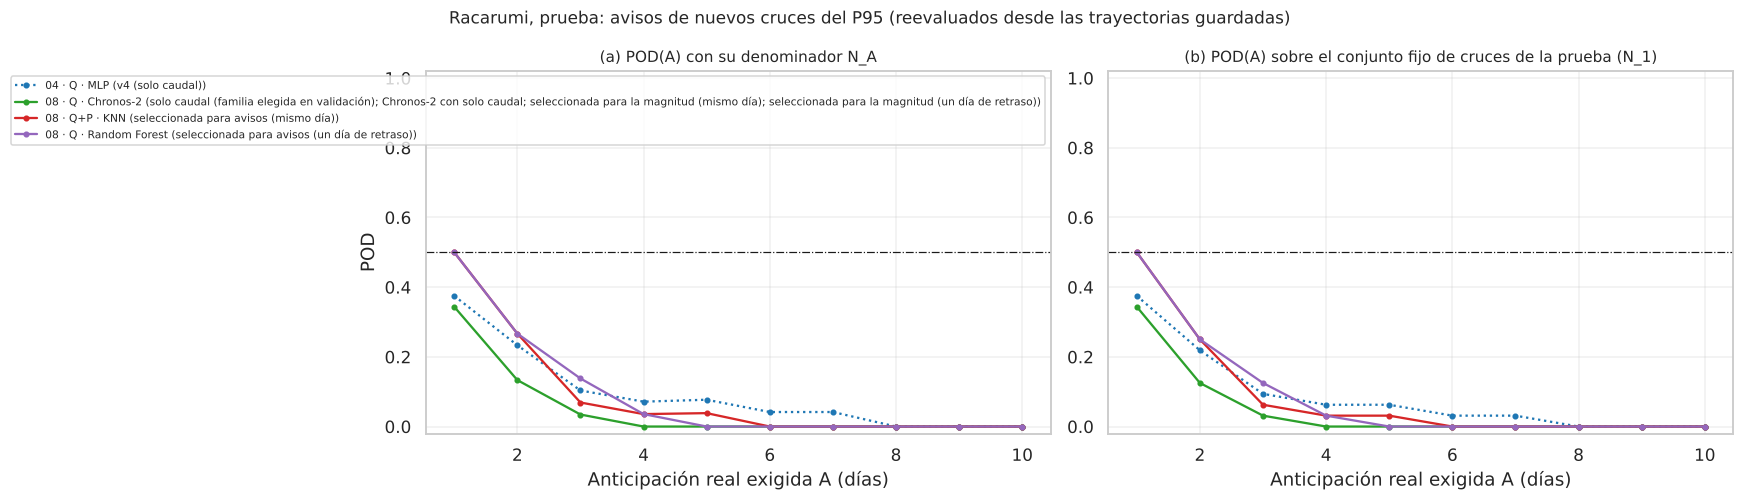

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6))
estilos = {'04': ':', '08': '-'}
for i, (kc, out) in enumerate(OUT.items()):
    if kc[1].endswith('Tendencia 3 días'):
        continue
    pa = out['por_A'].iloc[:10]
    et = f"{kc[0]} · {kc[1]} ({kc[2]})"
    ax[0].plot(pa.index, pa['POD'], estilos[kc[0]], marker='o', ms=3, color=plt.cm.tab10(i), label=et)
    ax[1].plot(pa.index, pa['POD_conjunto_fijo'], estilos[kc[0]], marker='o', ms=3, color=plt.cm.tab10(i))
for a, t_ in zip(ax, ['(a) POD(A) con su denominador N_A', '(b) POD(A) sobre el conjunto fijo de cruces de la prueba (N_1)']):
    a.axhline(AV['pod_min'], color='k', lw=0.8, ls='-.'); a.set_ylim(-0.02, 1.02); a.grid(True, alpha=0.3)
    a.set_xlabel('Anticipación real exigida A (días)'); a.set_title(t_, fontsize=10)
ax[0].set_ylabel('POD'); ax[0].legend(fontsize=7)
fig.suptitle('Racarumi, prueba: avisos de nuevos cruces del P95 (reevaluados desde las trayectorias guardadas)', fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig01_avisos_racarumi.png', dpi=200, bbox_inches='tight'); plt.show()

**Figura 1.** Racarumi, prueba: (a) POD(A) con su denominador variable N_A; (b) la misma detección dividida siempre entre los cruces del universo de prueba (N_1). Línea punteada: cuaderno 04 (solo caudal); continua: configuraciones del 08. Línea de trazos y puntos: POD = 0.5 del criterio.

**Interpretación (32 cruces evaluables en la prueba de Racarumi; reevaluación exacta de los conteos publicados):**
- **Solo caudal (04 y 08): ningún sistema alcanza el criterio** de anticipación útil (POD ≥ 0.5 con FAR ≤ 0.5). La tendencia de 3 días detecta 23 de 32, pero con 56 falsas alarmas.
- **Seleccionadas para avisos en el 08** (Q+P · KNN con la lluvia del mismo día; Q · Random Forest con un día de retraso): 16 de 32 cruces con FAR 0.57 y 0.61; **no cumplen**. Las seleccionadas para la magnitud (Q · Chronos-2) tampoco (11 de 32).
- **Configuraciones evaluadas, no elegidas:** con la lluvia del mismo día seis alcanzan 1 día de anticipación útil puntual (06 y 08 §6); solo Q+P · XGBoost también con los IC. Ninguna con un día de retraso.
- **Denominador:** en A = 1 los dos denominadores coinciden; con la lluvia futura observada (idealizado) la anticipación útil de XGBoost pasa de 17 días (denominador variable) a 6 (conjunto fijo de 32 cruces).
- **Tamshiyacu:** 2, 2 y 3 cruces evaluables en los bloques de calibración, comparación y prueba: no se evalúa un sistema de avisos.

---
## 4. ¿Qué deja fuera la condición de los 30 caudales futuros?
La muestra de evaluación conserva una emisión solo si están observados sus 30 caudales futuros, lo que permite comparar los 30 horizontes sobre las mismas fechas. Esta condición **no** entrega caudales futuros al modelo: solo selecciona qué emisiones se evalúan. Su efecto en la prueba se cuantifica con la **muestra extendida** de `comun.construir_muestras(..., exigir_todos=False)`, que conserva toda emisión con entrada válida y verifica cada horizonte con los objetivos que existan:
1. emisiones de prueba por horizonte en la muestra común y en la extendida;
2. NSE por horizonte de **persistencia y climatología** (no requieren entrenamiento; climatología hasta 2015, la de la prueba) en ambas muestras;
3. para avisos en Racarumi, días en que se podía emitir pero no se evaluó, y nuevos cruces que quedaron fuera del universo solo por esa condición;
4. en 06–07, si exigir lluvia futura disponible (para el escenario idealizado) quitó emisiones de prueba.

Los modelos entrenados no se ajustan en este cuaderno: su evaluación en la muestra extendida, para los seis modelos, todos los conjuntos y los 30 horizontes, está en los cuadernos 05 (sección 9: caudal aguas arriba) y 06 (sección 9: lluvia).

In [10]:
filas_h, filas_r = [], []
for e in EST:
    q, eps = D[e]['q'], D[e]['eps']
    esc = C.escalones(q)
    m = C.construir_muestras(q, L=C.L_VENTANA, H=H, esc=esc, eps=eps)
    mx = C.construir_muestras(q, L=C.L_VENTANA, H=H, esc=esc, eps=eps, exigir_todos=False)
    ip = C.particion(m)['pru']
    jx = np.where(mx.fechas > pd.Timestamp(C.FIN_VALIDACION))[0]
    assert m.fechas[ip].equals(D[e]['f_p'])
    clim = C.climatologia_referencia(q, 'prueba')             # política del proyecto: prueba → climatología hasta 2015
    pers_c, clim_c = C.pred_persistencia(m, ip), C.pred_climatologia(m, ip, clim)
    pers_x, clim_x = C.pred_persistencia(mx, jx), C.pred_climatologia(mx, jx, clim)
    ox = mx.q_obs[jx]
    for h in range(1, H + 1):
        ok = np.isfinite(ox[:, h - 1])
        filas_h.append({'estación': e, 'h': h, 'emisiones (común)': len(ip), 'emisiones (extendida)': int(ok.sum()),
                        'NSE persistencia (común)': C.nse(m.q_obs[ip, h - 1], pers_c[:, h - 1]),
                        'NSE persistencia (extendida)': C.nse(ox[ok, h - 1], pers_x[ok, h - 1]),
                        'NSE climatología (común)': C.nse(m.q_obs[ip, h - 1], clim_c[:, h - 1]),
                        'NSE climatología (extendida)': C.nse(ox[ok, h - 1], clim_x[ok, h - 1])})
    # emisiones posibles (entrada válida) frente a evaluadas, y cruces perdidos por la condición
    est_d = C.estado_diario(q, D[e]['P95'], D[e]['f_p'].min() - pd.Timedelta(days=8), q.index.max())
    el = C.elegibilidad(est_d)
    cr = C.cruces(est_d)
    cr = cr[(cr['fecha'] > D[e]['f_p'].min()) & cr['elegible']]
    pos_ev, pos_x = set(D[e]['f_p']), set(mx.fechas[jx])
    previo = cr['fecha'] - pd.Timedelta(days=1)
    en_U = previo.isin(pos_ev) & previo.map(lambda d: bool(el.get(d, False)))
    solo_cond = (~previo.isin(pos_ev)) & previo.isin(pos_x) & previo.map(lambda d: bool(el.get(d, False)))
    filas_r.append({'estación': e, 'días del periodo de prueba': int((mx.fechas[jx].max() - D[e]['f_p'].min()).days + 1),
                    'emisiones con entrada válida': len(jx), 'emisiones evaluadas (30 objetivos)': len(ip),
                    'excluidas solo por algún objetivo faltante': len(jx) - len(ip),
                    'nuevos cruces elegibles': len(cr), 'en el universo U': int(en_U.sum()),
                    'fuera de U solo por la condición de 30 objetivos': int(solo_cond.sum()),
                    'fechas de esos cruces': ', '.join(f'{d:%Y-%m-%d}' for d in cr.loc[solo_cond, 'fecha'])})
cob_h = pd.DataFrame(filas_h)
cob = pd.DataFrame(filas_r).set_index('estación')
cob_h.to_csv(RUTA_TAB / 'tabla_muestra_extendida_por_horizonte.csv', index=False); cob.to_csv(RUTA_TAB / 'tabla_cobertura_emisiones.csv')
cob

,días del periodo de prueba,emisiones con entrada válida,emisiones evaluadas (30 objetivos),excluidas solo por algún objetivo faltante,nuevos cruces elegibles,en el universo U,fuera de U solo por la condición de 30 objetivos,fechas de esos cruces
estación,,,,,,,,
Racarumi,2799,2789,2521,268,34,32,2,"2018-04-05, 2023-02-15"
Tamshiyacu,3652,3428,3252,176,3,3,0,


In [11]:
cob_h.set_index(['estación', 'h']).loc[(slice(None), [1, 3, 7, 15, 30]), :].round(3)

emisiones (común)  emisiones (extendida)  NSE persistencia (común)  NSE persistencia (extendida)  NSE climatología (común)  NSE climatología (extendida)
estación   h                                                                                                                                                           
Racarumi   1                2521                   2780                     0.837                         0.839                     0.460                         0.471
           3                2521                   2777                     0.573                         0.580                     0.460                         0.471
           7                2521                   2773                     0.262                         0.274                     0.460                         0.472
           15               2521                   2765                     0.019                         0.033                     0.463                         0.472
           30               2521                   2750                    -0.171                        -0.146                     0.488                         0.473
Tamshiyacu 1                3252                   3420                     0.998                         0.998                     0.786                         0.796
           3                3252                   3416                     0.986                         0.987                     0.785                         0.796
           7                3252                   3413                     0.942                         0.946                     0.785                         0.796
           15               3252                   3403                     0.821                         0.832                     0.786                         0.796
           30               3252                   3385                     0.532                         0.557                     0.792                         0.797

In [12]:
# 06–07: ¿exigir lluvia antecedente, con retraso y futura disponible quitó emisiones de prueba? (misma prueba que 01–02, comprobado en la sección 1)
filas = []
for e in EST:
    P = LL.cargar_lluvia(e)
    q, eps = D[e]['q'], D[e]['eps']
    m = C.construir_muestras(q, L=C.L_VENTANA, H=H, esc=C.escalones(q), eps=eps)
    ip = C.particion(m)['pru']
    ok = LL.matriz_lluvia(P, m.fechas)[2] & LL.matriz_lluvia(P, m.fechas, desfase=1)[2] & LL.matriz_futura(P, m.fechas, H)[1]
    filas.append({'estación': e, 'emisiones de prueba (01–02)': len(ip), 'con la lluvia que exige 06–07': int(ok[ip].sum()),
                  'lluvia disponible hasta': f'{P.dropna().index.max():%Y-%m-%d}', 'caudal disponible hasta': f'{q.dropna().index.max():%Y-%m-%d}'})
pd.DataFrame(filas).set_index('estación')

,emisiones de prueba (01–02),con la lluvia que exige 06–07,lluvia disponible hasta,caudal disponible hasta
estación,,,,
Racarumi,2521,2521,2025-12-31,2023-08-31
Tamshiyacu,3252,3252,2025-12-31,2025-12-31


**Interpretación:**
- **Emisiones fuera de la evaluación:** en la prueba, **268 de 2 789** emisiones con entrada válida de Racarumi (10 %) y **176 de 3 428** de Tamshiyacu (5 %) quedan fuera solo porque falta alguno de sus 30 caudales futuros (incluye los últimos 30 días de cada registro). Con la muestra extendida, cada horizonte gana 230–260 (Racarumi) y 130–170 (Tamshiyacu) emisiones verificables.
- **Efecto en las referencias** (climatología hasta 2015): el NSE de persistencia y climatología cambia **−0.02 a +0.03** entre las dos muestras, en los dos sentidos según el horizonte. Con los modelos entrenados (cuadernos 05 y 06, sección 9: 108 combinaciones × 30 horizontes) el NSE cambia 0.000 a +0.012 a 1–15 días; a 16–30 días, en Racarumi la extendida es hasta 0.03 más baja (la muestra común es algo favorable a plazos en que ningún modelo es útil).
- **Avisos:** **2 de los 34 nuevos cruces elegibles de Racarumi** (2018-04-05 y 2023-02-15) quedan fuera del universo solo por esta condición. Con los 34 (cuaderno 06, muestra extendida) las conclusiones no cambian.
- **Lluvia:** exigir lluvia antecedente, con retraso y futura **no quitó ninguna emisión de prueba** (PISCOp llega a 2025-12-31).

---
## 5. Distribución predictiva de Chronos-2: cobertura, amplitud y caudales altos
Con las bandas P10–P90 guardadas de la prueba, por bandas de horizonte: (a) cobertura en todos los pares emisión–horizonte, en los pares con caudal observado **sobre el P95** y en los ordinarios (ideal 80 %); (b) **amplitud** media de la banda y su razón frente a la banda **climatológica** P10–P90 del mismo día del año (datos hasta 2015, la política de la prueba; ventana ±15 días). Cuenta por separado los **pares emisión–horizonte** con Q > P95 y las **fechas objetivo únicas** (una misma fecha alta aparece en hasta 30 pares; ninguno de los dos es un número de eventos).
**Por qué:** una cobertura global cercana a la nominal puede convivir con bandas muy anchas o con fallos justo en las crecidas. La amplitud sola no mide el valor probabilístico: una banda igual de ancha que la climatológica puede estar mejor o peor ubicada. Por eso se agrega (c) la **puntuación de intervalo** de la banda P10–P90 (amplitud más la penalización por los observados fuera de ella; propia: premia bandas estrechas y bien ubicadas) frente a la de la banda climatológica en las mismas fechas: una razón < 1 indica más valor probabilístico que el calendario; su IC 90 % (bootstrap de meses de emisión, B = 1 000) dice si la diferencia se demuestra.

In [13]:
def banda_climatologica(q, fechas_obj, hasta=C.CLIMATOLOGIA_HASTA['prueba'], ventana=15):
    qe = q.loc[:hasta].dropna()
    doy = qe.index.dayofyear.to_numpy()
    lim = {}
    for d in range(1, 367):
        dist = np.minimum(np.abs(doy - d), 366 - np.abs(doy - d))
        x = qe.to_numpy()[dist <= ventana]
        lim[d] = (np.percentile(x, 10), np.percentile(x, 90))
    d = pd.DatetimeIndex(fechas_obj).dayofyear
    return np.array([lim[k][0] for k in d]), np.array([lim[k][1] for k in d])

def puntuacion_intervalo(o, l, u, alfa=0.2, media=True):
    # Puntuación de intervalo (Gneiting y Raftery, 2007) de la banda central P10–P90: amplitud + penalización 2/α por la
    # distancia del observado fuera de la banda. Es propia (premia bandas estrechas Y bien ubicadas); menor es mejor.
    s_ = (u - l) + 2 / alfa * (l - o) * (o < l) + 2 / alfa * (o - u) * (o > u)
    return float(np.mean(s_)) if media else s_

def ic_razon(fechas, a, b, B=B, semilla=C.SEMILLA):
    # IC 90 % de la razón de medias sum(a)/sum(b) por bootstrap de meses de emisión (a, b: una cifra por emisión)
    mes = pd.DatetimeIndex(fechas).to_period('M'); um = mes.unique()
    sa = np.array([a[mes == u].sum() for u in um]); sb = np.array([b[mes == u].sum() for u in um])
    k = np.random.default_rng(semilla).integers(0, len(um), (B, len(um)))
    return np.percentile(sa[k].sum(1) / sb[k].sum(1), [5, 95])

BANDAS = {'1–3 días': range(1, 4), '4–7 días': range(4, 8), '8–15 días': range(8, 16), '16–30 días': range(16, 31)}
filas = []
for e in EST:
    obs, fp, p95 = D[e]['obs'], D[e]['f_p'], D[e]['P95']
    for v, et in [('Q', 'solo caudal'), ('Q+P', 'Q+P (mismo día)'), ('Q+P|idealizado', 'Q+P con lluvia futura observada (idealizado)')]:
        pos = pd.DatetimeIndex(Z['chronos'][f'{e}|{v}|fechas']).get_indexer(fp)
        assert (pos >= 0).all()
        lo, hi = Z['chronos'][f'{e}|{v}|P10'][pos].astype(float), Z['chronos'][f'{e}|{v}|P90'][pos].astype(float)
        for nb_, hs in BANDAS.items():
            j = np.array(list(hs)) - 1
            o, l_, u_ = obs[:, j], lo[:, j], hi[:, j]
            dentro = (o >= l_) & (o <= u_)
            alto = o > p95
            fobj = np.concatenate([fp + pd.Timedelta(days=int(h)) for h in hs])
            cl, cu = banda_climatologica(D[e]['q'], fobj)
            ancho_clim = (cu - cl).reshape(len(hs), -1).T
            filas.append({'estación': e, 'información': et, 'banda': nb_, 'cobertura (todos)': dentro.mean(),
                          'cobertura (pares con Q > P95)': dentro[alto].mean() if alto.any() else np.nan,
                          'pares emisión–horizonte con Q > P95': C.conteo_altos(fp, np.where(np.isin(np.arange(H), j)[None, :], obs, -np.inf), p95)[0],
                          'fechas objetivo únicas con Q > P95': C.conteo_altos(fp, np.where(np.isin(np.arange(H), j)[None, :], obs, -np.inf), p95)[1],
                          'cobertura (pares con Q ≤ P95)': dentro[~alto].mean(),
                          'sobre P90 (pares con Q > P95)': (o[alto] > u_[alto]).mean() if alto.any() else np.nan,
                          'bajo P10 (pares con Q > P95)': (o[alto] < l_[alto]).mean() if alto.any() else np.nan,
                          'amplitud media (m³/s)': (u_ - l_).mean(), 'amplitud / climatológica': (u_ - l_).mean() / ancho_clim.mean(),
                          'cobertura de la banda climatológica (todos)': ((o >= cl.reshape(len(hs), -1).T) & (o <= cu.reshape(len(hs), -1).T)).mean(),
                          'puntuación de intervalo / climatológica': puntuacion_intervalo(o, l_, u_) / puntuacion_intervalo(o, cl.reshape(len(hs), -1).T, cu.reshape(len(hs), -1).T),
                          'IC90 de la razón (bootstrap de meses)': '{:.2f}–{:.2f}'.format(*ic_razon(fp, puntuacion_intervalo(o, l_, u_, media=False).mean(1),
                                                                   puntuacion_intervalo(o, cl.reshape(len(hs), -1).T, cu.reshape(len(hs), -1).T, media=False).mean(1)))})
prob = pd.DataFrame(filas).set_index(['estación', 'información', 'banda'])
prob.to_csv(RUTA_TAB / 'tabla_chronos_probabilistico_condiciones.csv')
prob.round(2)

cobertura (todos)  cobertura (pares con Q > P95)  pares emisión–horizonte con Q > P95  fechas objetivo únicas con Q > P95  \
estación   información                                  banda                                                                                                                                   
Racarumi   solo caudal                                  1–3 días                 0.79                           0.53                                  444                                 148   
                                                        4–7 días                 0.79                           0.44                                  593                                 149   
                                                        8–15 días                0.78                           0.41                                 1186                                 149   
                                                        16–30 días               0.78                           0.44                                 2108                                 145   
           Q+P (mismo día)                              1–3 días                 0.77                           0.53                                  444                                 148   
                                                        4–7 días                 0.76                           0.44                                  593                                 149   
                                                        8–15 días                0.76                           0.42                                 1186                                 149   
                                                        16–30 días               0.76                           0.46                                 2108                                 145   
           Q+P con lluvia futura observada (idealizado) 1–3 días                 0.79                           0.55                                  444                                 148   
                                                        4–7 días                 0.81                           0.55                                  593                                 149   
                                                        8–15 días                0.82                           0.64                                 1186                                 149   
                                                        16–30 días               0.83                           0.69                                 2108                                 145   
Tamshiyacu solo caudal                                  1–3 días                 0.74                           0.80                                  231                                  77   
                                                        4–7 días                 0.79                           0.90                                  308                                  77   
                                                        8–15 días                0.77                           0.85                                  616                                  77   
                                                        16–30 días               0.75                           0.65                                 1155                                  77   
           Q+P (mismo día)                              1–3 días                 0.81                           0.79                                  231                                  77   
                                                        4–7 días                 0.82                           0.94                                  308                                  77   
                                                        8–15 días                0.79                           0.89                                  616                                  77   
               

**Interpretación:**
- **Unidades:** cada fila cuenta **pares emisión–horizonte**; en Racarumi, los 444–2 108 pares con caudal sobre el P95 corresponden a solo 145–149 fechas objetivo distintas, de pocos eventos.
- **Racarumi: la cobertura global es cercana a la nominal (76–79 %; la banda climatológica cubre 82 %), pero en los pares con caudal sobre el P95 cae a 41–53 %** sin lluvia futura (55–69 % con lluvia futura observada). Casi todos los fallos son caudales **por encima** del P90.
- **Valor probabilístico** (razón de puntuaciones de intervalo frente a la banda climatológica, con IC 90 %): a 1–3 días la puntuación es **40 % menor** (0.57–0.60); a 4–7 días, 0.84–0.86; **desde 8 días ya no se demuestra** y a 16–30 días la razón es 1.02–1.03 con IC 0.98–1.07. Con lluvia futura observada sí (0.58).
- **Tamshiyacu:** cobertura de 74–82 % y de 65–99 % en los pares altos (3 eventos: descriptivo); la puntuación es 0.13 de la climatológica a 1–3 días, 0.30–0.32 a 4–7 y 0.56–0.62 a 8–15; a 16–30 días, IC que incluyen 1.
- **Por tanto, la cobertura agregada cercana a la nominal no demuestra bandas calibradas** para los caudales elevados ni para los plazos largos.

---
## 6. Respuestas del estudio

| Pregunta | Respuesta con la evidencia disponible | Alcance |
|---|---|---|
| **P1** Horizonte útil de la magnitud con caudal local | **Racarumi 6 días** (LSTM; 4–6 según el modelo); **Tamshiyacu ≥ 30 días** (XGBoost). La diferencia entre ríos es mucho mayor que entre modelos. | Prueba desde 2016-01 (Racarumi hasta 2023-08; Tamshiyacu hasta 2025-12), consultada durante el desarrollo del proyecto. H cota: cota inferior unilateral aproximada del bootstrap de meses con predicciones fijas. |
| **P2** Anticipación de nuevos cruces con caudal local | **Racarumi: no se alcanzó el criterio** (MLP 12 de 32, FAR 0.54). **Tamshiyacu: 3 de 3 cruces con 3 días** (KNN). | Racarumi: 32 de 34 cruces elegibles evaluados. Tamshiyacu: descriptivo (3 eventos). |
| **P3** Estaciones aguas arriba inmediatas | **San Regis reduce el error de Tamshiyacu 33–45 % a 1–3 días con los seis modelos** (y 18–25 % a 4–7); con un día de retraso, 7–22 %; el horizonte útil casi no cambia. **Requena: sin reducción demostrada** (con Random Forest y KNN aumenta el error a 1–3 días), tampoco sobre la lluvia. **Cirato: no se demostró una mejora** con los seis modelos ni con Chronos-2 (13 meses). | Efecto en avisos no evaluable (3 eventos). |
| **P4** Lluvia de la cuenca | Racarumi: con la lluvia **del mismo día** el error a 1–3 días baja 12–27 % con los seis modelos y seis configuraciones alcanzan **1 día de anticipación útil puntual** (con los IC, solo una); **con un día de retraso** el beneficio cae casi por completo. Tamshiyacu: la lluvia reduce el error 2–18 % (según el modelo y la banda), también con retraso, y complementa a San Regis a 4–30 días; la validación no lo distingue. **Lluvia futura conocida (idealizado):** 62–69 % menos error en Racarumi; avisos de alrededor de una semana para una parte de los cruces (6 días con el conjunto fijo). | El escenario «mismo día» **no está demostrado como operativo**. El idealizado es un potencial con XGBoost, la regresión lineal y Chronos-2, no un límite universal. |
| **P5** Chronos-2 con pesos publicados, sin ajuste local | En magnitud resulta seleccionado en Racarumi por su ventaja en validación, pero **no mantiene esa ventaja relativa en la prueba** (la mitad de los candidatos son mejores); en Tamshiyacu sus configuraciones son **peores** que la seleccionada en 34 de 36 comparaciones (configuraciones distintas en fechas comunes); **en avisos participa como candidato pero no resulta seleccionado** (CSI 0.38–0.45 en validación; 10–15 de 32 cruces en la prueba, FAR > 0.5). Bandas con cobertura cercana a la nominal en Racarumi pero **41–53 % en los pares sobre el P95** y sin ventaja sobre la climatología desde 8 días. | Contexto elegido en validación (512 días en Tamshiyacu, limitado por los escalones de nivel; con 2 048 mejora, sensibilidad posterior). |
| **P6** Selección final (08) | **Magnitud:** Racarumi Q · Chronos-2 (los dos escenarios; NSE medio de prueba 0.490, horizonte útil 5 días); Tamshiyacu con San Regis Q · KNN (0.906, ≥ 30 días); en el periodo común con Requena Q+SR · KNN (mismo día) y Q · KNN (retraso), también con las combinaciones de lluvia con Requena en competencia. **Avisos:** Racarumi Q+P · KNN (mismo día) y Q · Random Forest (retraso), que **no cumplen el criterio en la prueba**; Tamshiyacu, no se selecciona. **Ninguna selección coincide con lo mejor de la prueba**: con la misma familia, las entradas externas reducen el error de corto plazo, pero la validación disponible no basta para elegirlas de forma confiable. | Selecciones poco nítidas: entre 1 y 12 candidatos equivalentes al mayor y entre 7 y 20 inconclusos en validación (que no son equivalencias); IC individuales; prueba ya consultada; disponibilidad del mismo día supuesta. |

**Pregunta principal** (respuesta de una comparación académica de configuraciones; no es un sistema operativo de alerta)**.** En estas dos estaciones **el río pesa más que el modelo** en el horizonte útil: Tamshiyacu da un mes de pronóstico útil de magnitud y Racarumi alrededor de una semana. Agregar información mejora la magnitud de corto plazo con el mismo modelo (San Regis en Tamshiyacu; lluvia del mismo día en Racarumi), y en Racarumi varias configuraciones evaluadas dan **1 día de aviso** de nuevos cruces si la lluvia del día de emisión estuviera disponible. Pero **la selección hecha solo en validación —la que exige el protocolo— no recupera esas mejoras**: elige solo caudal (o Chronos-2 en Racarumi, que no se sostiene en la prueba) y ningún sistema de avisos elegido de antemano cumple el criterio. Más anticipación requeriría pronósticos de lluvia (potencial de alrededor de una semana para una parte de los cruces en el escenario idealizado), estaciones más lejanas en la red y, sobre todo, más eventos para poder elegir con confianza.

In [14]:
# Registro de los archivos usados, todos verificados contra el manifiesto ANTES de leerlos (sección 1)
huellas = pd.DataFrame(LEIDOS).drop_duplicates('archivo').set_index('archivo')
huellas.to_csv(RUTA_TAB / 'tabla_archivos_leidos.csv')
pd.DataFrame(INSUMOS).to_csv(RUTA_TAB / 'tabla_insumos_verificados.csv', index=False)
limpio = lambda d: json.loads(pd.DataFrame(d).to_json(orient='records', force_ascii=False))
resumen = {'version': C.VERSION, 'revision': C.REVISION, 'rapido': C.es_rapido(), 'etapa': 'síntesis integral (cuaderno 09)',
           'archivos_leidos': len(huellas), 'archivos_validados_contra_el_manifiesto': int(huellas['validado'].sum()),
           'insumos_originales_y_codigo_verificados': int(sum(f['validado'] for f in INSUMOS)), 'insumos_registrados': len(INSUMOS),
           'climatologia_hasta': C.CLIMATOLOGIA_HASTA, 'verificaciones_08': {'total': len(v08), 'correctas': int((v08['resultado'] == 'correcto').sum())},
           'seleccion_final_magnitud': limpio(sel_m.reset_index()), 'seleccion_final_avisos': limpio(sa08.reset_index()),
           'avisos_reproducidos': len(CAND), 'avisos_racarumi': limpio(avisos.reset_index()),
           'cobertura_emisiones': limpio(cob.reset_index())}
(SAL / 'sintesis' / 'resumen.json').write_text(json.dumps(resumen, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
print(f"{len(huellas)} archivos leídos; {int(huellas['validado'].sum())} validados contra el manifiesto antes de usarlos")

25 archivos leídos; 25 validados contra el manifiesto antes de usarlos


---
## 7. Límites que la integración no resuelve
- **Integrar una etapa no aumenta la evidencia.** Cirato tiene 13 meses con fechas confiables y Tamshiyacu 3 eventos sobre el P95 en la prueba: sus conclusiones sobre avisos siguen siendo exploratorias o no evaluables. En Racarumi, 13 y 14 cruces en los bloques de validación no bastan para elegir un sistema de avisos.
- **Prueba ya consultada.** El periodo de prueba (desde 2016-01) se consultó durante el desarrollo del proyecto; las reglas se fijaron antes de la evaluación final y la prueba no intervino en ninguna selección, pero no es una prueba independiente. Por eso la síntesis distingue lo seleccionado en validación de lo mejor observado en la prueba y no reemplaza lo primero por lo segundo.
- **P95 ≠ inundación.** El estudio evalúa caudales elevados bajo una definición estadística (P95 del entrenamiento), no inundaciones ni daños.
- **Representaciones distintas.** Las familias reciben las mismas fuentes y disponibilidad, pero cada una con su representación (acumulados en logaritmos, ventanas diarias o series en unidades físicas con contextos largos); las diferencias entre familias no aíslan el efecto del algoritmo.
- **No es un sistema operativo.** Las configuraciones de avisos se evaluaron retrospectivamente con datos depurados; un sistema de alerta necesitaría datos en tiempo real, más eventos y una validación prospectiva.
- **Disponibilidad de datos en operación.** El escenario «mismo día» supone lluvia y caudal de San Regis del día t al emitir; en 2019 San Regis y Requena dejaron de medir justo al empezar la crecida.
- **Escenario idealizado.** La lluvia futura observada mide un potencial bajo esa condición con tres modelos; un pronóstico de lluvia real tiene error que crece con el plazo.
- **Selecciones poco nítidas.** Muchos candidatos son equivalentes al mayor o quedan inconclusos en validación (sin evidencia suficiente para ordenarlos); el contexto de Chronos-2 se eligió en el mismo bloque de selección; la selección en Racarumi cambia con el arranque del IPA (06) y con la presencia de Chronos-2 (08).
- **No implementado por diseño:** índices antecedentes sin la lluvia; Cirato solo exploratorio.